# Comparación de evaluación: validación cruzada y etiquetas construidas por regla

Cuaderno didáctico (español). Compara, **con los mismos datos, las mismas features y los mismos modelos**, tres preguntas distintas que suelen mezclarse:

1. **¿Qué ejecuta hoy el repo del TP?** (rama, SHA, archivos, evidencias y reproducción de su evaluación).
2. **¿La evaluación cumple el protocolo del curso?** (test intocable, CV con 5 folds estratificados **solo sobre train**, preprocesamiento dentro del `Pipeline`, tuning con `GridSearchCV` solo en train, sin elegir modelo con test).
3. **¿Qué significa el 1.0?** (aprendizaje supervisado con etiquetas construidas por una regla determinista, separado de la pregunta de CV; comparación con la regla exacta y con un baseline de mayoría; auditoría de fuga).

Reglas de este cuaderno (sin excepciones):

- El repo del TP es **la raíz de este repo** (este cuaderno vive en `notebooks/` y resuelve la raíz de forma portable, sin rutas absolutas): este cuaderno lee el CSV, `git` y el script de comparación pero **no escribe fuera de `docs/comparacion-evaluacion/`** (se usa `PYTHONDONTWRITEBYTECODE=1` y el script del repo se corre sin `--figures`).
- **Prohibido**: clustering para etiquetar, inventar etiquetas, agregar ruido, o seleccionar modelos mirando el test.
- Un 1.0 sobre etiquetas sintéticas **no afirma causalidad ni utilidad operativa real**; mide ajuste a la regla declarada.
- Cada afirmación sobre el curso cita **archivo y celda**; cada afirmación sobre el repo cita **archivo/línea o evidencia ejecutada**.

In [1]:
import hashlib
import json
import random
import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Portable: funciona desde la raíz del repo y desde notebooks/ (nbconvert ejecuta
# el kernel con cwd = directorio del notebook). Sin rutas absolutas para datos.
ROOT = next(r for r in [Path.cwd(), Path.cwd().parent] if (r / "dataset" / "salida" / "tramos.csv").is_file())
REPO = ROOT  # alias: este cuaderno vive dentro del repo
# Curso Intro-A-ML: material externo, solo se cita por archivo/celda (sin lectura con ruta absoluta).
CURSO = None
CSV = ROOT / "dataset" / "salida" / "tramos.csv"
SEED = 0
CLASES = ["baja", "media", "alta"]
FEATURES = [
    "cantidad_contenedores",
    "dias_desde_ultima_recoleccion",
    "tipo_zona",
    "historico_quejas_vecinales",
]
TARGET = "prioridad_recoleccion"

print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("ROOT:", ROOT, "| CSV relativo:", CSV.relative_to(ROOT), "| seed:", SEED)

sklearn 1.9.1 | pandas 3.0.2 | numpy 2.3.5
ROOT: /home/nacho/Documentos/tpMachineLearningGrafo | CSV relativo: dataset/salida/tramos.csv | seed: 0


## 1. Qué ejecuta el repo actual (rama, SHA, archivos, evidencias)

Todo lo que sigue es **lectura**: comandos `git` de consulta, lectura del CSV y del `metadata.json`, y cálculo de SHA. Nada escribe en el repo.

In [2]:
def git_ro(*args):
    """Ejecuta git -C <repo> en modo solo lectura (consulta, sin fetch ni checkout)."""
    r = subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    return r.stdout.strip()


RAMA = git_ro("rev-parse", "--abbrev-ref", "HEAD")
SHA = git_ro("rev-parse", "HEAD")
STATUS = git_ro("status", "--short")
LOG = git_ro("log", "--oneline", "-5")
print("rama:", RAMA)
print("SHA :", SHA)
print("status (limpio salvo untracked ajenos a ML = OK):", repr(STATUS))
print("últimos commits:")
print(LOG)

rama: main
SHA : 97f10409a29e231dd01bf5c06ae36dd32f58c65b
status (limpio salvo untracked ajenos a ML = OK): 'M docs/comparacion-evaluacion/tabla_comparativa.csv\n M notebooks/comparacion_evaluacion.ipynb\n?? backend/artifacts/\n?? package-lock.json\n?? package.json\n?? scripts/generate_arbol_artifact.py'
últimos commits:
97f1040 Merge pull request #34 from Nachom3/30-frontend-demo
872c316 Merge pull request #33 from Nachom3/29-api-v1
1dca11e fix(notebook): marcar plan_route como implementado (#29) en smoke 12
ba316d1 Merge pull request #35 from Nachom3/notebooks-comparacion-evaluacion
565df99 feat(frontend): completar demo integrada a API v1 real (#30)


In [3]:
META = json.loads((REPO / "dataset" / "salida" / "metadata.json").read_text())
sha_csv = hashlib.sha256(CSV.read_bytes()).hexdigest()
sha_nodos = hashlib.sha256((REPO / "dataset" / "salida" / "nodos.csv").read_bytes()).hexdigest()
print("metadata.json ->", json.dumps({k: META[k] for k in ["t0", "seed", "conteos"]}, ensure_ascii=False))
print("SHA tramos.csv calculado:", sha_csv)
print("SHA esperado metadata :", META["output_sha256"]["tramos.csv"])
assert sha_csv == META["output_sha256"]["tramos.csv"], "el CSV cambió respecto a metadata"
assert sha_nodos == META["output_sha256"]["nodos.csv"], "nodos.csv cambió respecto a metadata"
print("OK: los CSV coinciden con metadata.json (reproducibilidad + trazabilidad SHA).")
print("regla v1 documentada:", META["regla_v1"]["score"], "| recalibrada:", META["regla_v1"]["umbrales_recalibrados"])
print("\nArchivos del pipeline ML (lo que el repo ejecuta):")
for p in [
    "scripts/train_compare.py",  # entrada delgada: prepara, compara, elige en validación, evalúa 1 vez en test
    "backend/src/collection/adapters/datasets/ml_preparation.py",  # validación + quejas + split 60/20/20 + preprocessor SIN ajustar
    "backend/src/collection/adapters/datasets/synthetic_complaints.py",  # regla: quejas [0,3] y score con umbrales 0/2
    "backend/src/collection/adapters/datasets/partitioning/stratified_split.py",  # train_test_split estratificado 2 etapas
    "backend/src/collection/adapters/models/model_specs.py",  # 4 modelos + baseline, pipelines UNFITTED, grillas chicas
    "backend/src/collection/adapters/models/sklearn_evaluator.py",  # CV5 solo train, GridSearchCV (f1_macro), test un solo uso
    "backend/src/collection/application/models/evaluation_protocol.py",  # protocolo: seed 0, 5 folds, estratificado
    "docs/modelo-comparacion.md",  # informe de resultados del repo
    "notebooks/10_entrenamiento_modelos.ipynb",  # notebook del repo (a la fecha sin outputs guardados)
]:
    print(f"  {p} ({(REPO / p).stat().st_size} bytes)")

metadata.json -> {"t0": "2026-10-23", "seed": 42, "conteos": {"nodos": 209, "tramos": 297, "contenedores_piloto": 129}}
SHA tramos.csv calculado: c332015ed38a063344ab86f39d11238ae66126fb4ccb654ce3d96e589b4567d8
SHA esperado metadata : c332015ed38a063344ab86f39d11238ae66126fb4ccb654ce3d96e589b4567d8
OK: los CSV coinciden con metadata.json (reproducibilidad + trazabilidad SHA).
regla v1 documentada: 2*dias + 1*contenedores + zona_w (comercial 2, industrial 1, residencial 0) | recalibrada: {'baja_max': 0, 'media_max': 2}

Archivos del pipeline ML (lo que el repo ejecuta):
  scripts/train_compare.py (6691 bytes)
  backend/src/collection/adapters/datasets/ml_preparation.py (9859 bytes)
  backend/src/collection/adapters/datasets/synthetic_complaints.py (2896 bytes)
  backend/src/collection/adapters/datasets/partitioning/stratified_split.py (5380 bytes)
  backend/src/collection/adapters/models/model_specs.py (4582 bytes)
  backend/src/collection/adapters/models/sklearn_evaluator.py (19770 byt

## 2. Reproducción de la evaluación actual (sin tocar el repo)

Ejecutamos el script del repo **tal cual**, solo lectura: lee el CSV, imprime métricas, no recibe `--figures` (no escribe nada). Se usa `PYTHONDONTWRITEBYTECODE=1` para no crear ni tocar `.pyc` dentro del repo. Si estos números no coincidieran con `docs/modelo-comparacion.md`, la evidencia mandaría, no el informe.

In [4]:
import os

env = dict(os.environ, PYTHONDONTWRITEBYTECODE="1", PYTHONPATH=str(REPO / "backend" / "src"))
r = subprocess.run(
    ["python3", "scripts/train_compare.py", "--source", "dataset/salida/tramos.csv", "--seed", "0"],
    cwd=str(REPO), capture_output=True, text=True, env=env,
)
assert r.returncode == 0, r.stderr
print(r.stdout)

REPRO = {}
REPRO["sizes"] = re.search(r"sizes=(\{.*?\})", r.stdout).group(1)
REPRO["dist"] = re.search(r"dist=(\{.*?\})", r.stdout).group(1)
REPRO["cv"] = re.search(r"cv: pedidos=(\d+) usados=(\d+)", r.stdout).groups()
REPRO["modelos"] = re.findall(
    r"^(arbol|logistica|knn|svc): cv_acc=(\S+) cv_f1=(\S+) val_acc=(\S+) val_f1=(\S+) best=(\{.*?\})",
    r.stdout, flags=re.M,
)
REPRO["baseline"] = re.search(r"baseline\(mayoria\): acc=(\S+) f1=(\S+)", r.stdout).groups()
REPRO["elegido"] = re.search(r"elegido por validacion: (\w+)", r.stdout).group(1)
REPRO["test"] = re.search(r"test \(un solo uso, (\w+)\): acc=(\S+) f1=(\S+)", r.stdout).groups()
assert REPRO["elegido"] == "arbol" and float(REPRO["test"][1]) == 1.0 and float(REPRO["test"][2]) == 1.0
assert REPRO["cv"] == ("5", "5"), "se pidieron 5 folds y se usaron 5, solo dentro de train"
print("Verificación: el script reproduce lo documentado (elegido=arbol por validación, test 1.0 un solo uso, CV 5/5 en train).")

seed=0 sizes={'train': 178, 'validation': 59, 'test': 60}
dist={'train': {'baja': 77, 'media': 56, 'alta': 45}, 'validation': {'baja': 26, 'media': 18, 'alta': 15}, 'test': {'baja': 26, 'media': 19, 'alta': 15}}
cv: pedidos=5 usados=5 (solo dentro de train)
arbol: cv_acc=0.9944±0.0111 cv_f1=0.9932±0.0136 val_acc=1.0000 val_f1=1.0000 best={'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_split': 2}
  matriz_val(arbol)=[[26, 0, 0], [0, 18, 0], [0, 0, 15]]
    baja: VP=26 FP=0 FN=0 VN=33
    media: VP=18 FP=0 FN=0 VN=41
    alta: VP=15 FP=0 FN=0 VN=44
logistica: cv_acc=0.9660±0.0331 cv_f1=0.9619±0.0367 val_acc=0.9322 val_f1=0.9268 best={'logisticregression__C': 0.5}
  matriz_val(logistica)=[[26, 0, 0], [2, 16, 0], [0, 2, 13]]
    baja: VP=26 FP=2 FN=0 VN=31
    media: VP=16 FP=2 FN=2 VN=39
    alta: VP=13 FP=0 FN=2 VN=44
knn: cv_acc=0.9775±0.0276 cv_f1=0.9743±0.0315 val_acc=0.9661 val_f1=0.9680 best={'kneighborsclassifier__n_neighbors': 7}
  matriz_val(knn)=

### 2.1 Cómo interpretar las métricas

En un problema de tres clases, las métricas por clase se calculan considerando una clase como positiva y las otras dos como negativas. Por ejemplo, para la clase **alta** (curso S5, `slides.pdf`, diapositivas 6-16; `notebook-1-metricas.ipynb`, celdas 13-14 y 18-24):

| Término | Significado para la clase alta |
|---|---|
| **VP**: verdadero positivo | Predijo alta y era alta. |
| **FP**: falso positivo | Predijo alta, pero era media o baja. |
| **FN**: falso negativo | Era alta, pero predijo media o baja. |
| **VN**: verdadero negativo | No era alta y tampoco predijo alta. |

- **Accuracy**: proporción de predicciones correctas sobre el total de tramos.
- **Precision**: de los tramos que predijo en una clase, qué proporción pertenecía realmente a ella: `VP / (VP + FP)`.
- **Recall**: de los tramos que realmente pertenecían a una clase, qué proporción detectó: `VP / (VP + FN)`.
- **F1**: media armónica de precision y recall: `2 * precision * recall / (precision + recall)`. El **F1 macro** promedia el F1 de las tres clases, dando el mismo peso a cada una.

### 2.2 Árbol y KNN: lectura de la validación guardada

La tabla resume la **salida guardada de la celda anterior**: validación de **59 tramos** del script, con `seed=0` y clases en orden baja, media y alta. Son los resultados de una sola partición de validación, **no** del test ni de la comparación propia de cinco folds de §5. Si cambian los datos o la ejecución, esta instantánea debe actualizarse.

| Modelo | Clase | VP | VN | FP | FN | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| Árbol | baja | 26 | 33 | 0 | 0 | 1,0000 | 1,0000 | 1,0000 |
| Árbol | media | 18 | 41 | 0 | 0 | 1,0000 | 1,0000 | 1,0000 |
| Árbol | alta | 15 | 44 | 0 | 0 | 1,0000 | 1,0000 | 1,0000 |
| KNN | baja | 26 | 31 | 2 | 0 | 0,9286 | 1,0000 | 0,9630 |
| KNN | media | 16 | 41 | 0 | 2 | 1,0000 | 0,8889 | 0,9412 |
| KNN | alta | 15 | 44 | 0 | 0 | 1,0000 | 1,0000 | 1,0000 |

El árbol acertó **59/59**: accuracy `1,0000` y F1 macro `1,0000`. KNN acertó **57/59**: accuracy `0,9661` y F1 macro `0,9680`. Sus dos errores fueron tramos de prioridad **media** predichos como **baja**. Para media detectó 16 de 18 casos, por eso su recall es `16/18 = 0,8889`. Ambos detectaron los 15 casos etiquetados como alta en esta validación.

Una sola partición no demuestra que el árbol sea siempre mejor; §5 compara los modelos mediante CV con otro conjunto de entrenamiento. Además, estas métricas miden coincidencia con **etiquetas sintéticas construidas por regla**, no validan por sí solas la necesidad real de recolección.

## 3. Aprendizaje supervisado y etiquetas construidas por regla

### 3.1 El problema es supervisado (y eso es independiente de la CV)

Aprendizaje **supervisado** = aprender una función `X -> y` a partir de ejemplos etiquetados `(X, y)`.
Acá `X` son 4 columnas del tramo y `y` es `prioridad_recoleccion` con 3 clases (`baja/media/alta`).
La **validación cruzada** es otra pregunta distinta: *cómo medimos* si lo aprendido generaliza, sin mirar el test. No confundir ambas: una etiqueta puede ser perfectamente válida como objetivo supervisado aunque el 1.0 no pruebe nada operativo (ver §3.3 y §6).

### 3.2 La etiqueta la construye una regla determinista conocida

El CSV trae una etiqueta v1; el repo la **reconstruye** sumando quejas sintéticas (sorteo anónimo uniforme `[0,3]` por contenedor, suma por tramo, cero si no hay contenedores; RNG `random.Random(sha256(seed:tramo_id))`, estable por tramo e independiente del orden) y aplicando:

`score = 2*dias + 1*contenedores + 1*zona_w + 2*quejas`, `zona_w = {residencial: 0, industrial: 1, comercial: 2}`, `baja <= 0`, `media 1..2`, `alta > 2`

Fuente repo: `synthetic_complaints.py:21-33,62-75` + `ml_preparation.py:155`. El Enunciado anticipa esto: con datos sintéticos se declaran las reglas y *el modelo descubrirá esas reglas* (esperable, hay que decirlo). Reimplementamos la regla acá de forma **independiente** (sin importar código del repo) para verificarla:

In [5]:
ZONA_W = {"residencial": 0, "industrial": 1, "comercial": 2}


def quejas_tramo(n_cont, tramo_id, seed=SEED):
    """Suma de sorteos anónimos [0,3] por contenedor (réplica documentada de la regla)."""
    key = hashlib.sha256(f"{seed}:{tramo_id}".encode()).digest()
    rng = random.Random(int.from_bytes(key[:8], "big"))
    return sum(rng.randint(0, 3) for _ in range(n_cont))


def etiqueta_por_regla(dias, cont, zona, quejas):
    score = 2 * dias + cont + ZONA_W[zona] + 2 * quejas
    return "baja" if score <= 0 else ("media" if score <= 2 else "alta")


df = pd.read_csv(CSV)  # solo lectura del CSV del repo
print("filas:", len(df), "| columnas:", list(df.columns))
print("\nEtiqueta ORIGINAL del CSV (regla v1 sin quejas):")
print(df["prioridad_recoleccion"].value_counts().reindex(CLASES))

enriquecido = df.copy()
enriquecido["historico_quejas_vecinales"] = [
    quejas_tramo(int(n), str(t)) for n, t in zip(df["cantidad_contenedores"], df["tramo_id"])
]
enriquecido["etiqueta_reconstruida"] = [
    etiqueta_por_regla(d, c, z, q)
    for d, c, z, q in zip(
        df["dias_desde_ultima_recoleccion"], df["cantidad_contenedores"],
        df["tipo_zona"], enriquecido["historico_quejas_vecinales"],
    )
]
dist = enriquecido["etiqueta_reconstruida"].value_counts().reindex(CLASES)
print("\nEtiqueta RECONSTRUIDA con quejas (la que usa el repo como y):")
print(dist)
assert dist.to_dict() == {"baja": 129, "media": 93, "alta": 75}, "debe coincidir con docs/modelo-comparacion.md"
print("\nOK: la reimplementación independiente reproduce la distribución documentada (129/93/75).")
print("Cruce v1 (CSV) vs reconstruida (y del repo):")
print(pd.crosstab(df["prioridad_recoleccion"], enriquecido["etiqueta_reconstruida"]))

filas: 297 | columnas: ['tramo_id', 'nodo_origen', 'nodo_destino', 'longitud_m', 'nombre_calle', 'tipo_zona', 'cantidad_contenedores', 'dias_desde_ultima_recoleccion', 'prioridad_recoleccion']

Etiqueta ORIGINAL del CSV (regla v1 sin quejas):
prioridad_recoleccion
baja     129
media    125
alta      43
Name: count, dtype: int64

Etiqueta RECONSTRUIDA con quejas (la que usa el repo como y):
etiqueta_reconstruida
baja     129
media     93
alta      75
Name: count, dtype: int64

OK: la reimplementación independiente reproduce la distribución documentada (129/93/75).
Cruce v1 (CSV) vs reconstruida (y del repo):
etiqueta_reconstruida  alta  baja  media
prioridad_recoleccion                   
alta                     43     0      0
baja                      0   129      0
media                    32     0     93


### 3.3 Por qué el árbol puede dar 1.0 sin que haya trampa

La etiqueta es una función **determinista y por umbrales** de `X`. Un árbol de decisión con `max_depth=None` puede representar cortes por umbrales de forma exacta, así que el 1.0 es *ajuste perfecto a la regla declarada*, no evidencia de desempeño en calle. La prueba de que no es memorización de IDs está en §4 (el `tramo_id` nunca entra a `X`) y en que la **regla exacta aplicada a mano** también da 1.0 (ver §5.3): cualquier modelo que aproxime bien la regla llega al mismo lugar.

## 4. Auditoría de fuga (leakage): qué se excluyó y por qué

| Posible fuga | Verificación en este cuaderno | Resultado |
|---|---|---|
| Columna `score` como feature | `"score" in df.columns` y en `FEATURES` | No existe como columna: se deriva en memoria; **no hay fuga por score persistido** |
| IDs (`tramo_id`, nodos) como features | intersección con `FEATURES` | `tramo_id`/`nodo_origen`/`nodo_destino` **excluidos** de `X` (solo trazabilidad/auditoría). *Diferencia registrada*: el repo tampoco los usa (`ml_preparation.py:35 FEATURE_COLUMNS`) |
| Columnas derivadas del target | `prioridad_recoleccion_original` (auditoría #9) en `X` | No entra a `X`: solo viven las 4 features en `FEATURES`. La circularidad regla↔etiqueta es **intencional y declarada** (el Enunciado la anticipa), distinta de fuga train/test |
| Columnas reales no usadas (`longitud_m`, `nombre_calle`) | existen en el CSV, fuera de `X` | Excluidas en ambas implementaciones; no aportan ni fugan (constan como diferencia potencial, no como fuga) |
| Preprocesamiento ajustado con todo el dataset | codificación solo con train (§5.2), `StandardScaler` dentro del `Pipeline` por fold (curso S5 celdas 26-27) | Sin fuga: nada que aprenda de datos vive fuera del pipeline |
| Test usado para decidir | bandera `test_tocado`: el test se predice **una sola vez** al final (§5.3) | Sin fuga: la elección del modelo usa solo CV dentro de train |

In [6]:
EXCLUIDAS = ["tramo_id", "nodo_origen", "nodo_destino", "longitud_m", "nombre_calle", TARGET]
assert "score" not in df.columns, "no debe existir columna score persistida"
assert set(FEATURES).isdisjoint(EXCLUIDAS), "features e IDs/target no deben cruzarse"
assert enriquecido["etiqueta_reconstruida"].isna().sum() == 0
assert (df["tramo_id"].nunique() == len(df)) and (df.duplicated().sum() == 0)
print("Fuga por score/IDs/duplicados: NO detectada (ver tabla de §4).")
print("Features usadas aquí y en el repo:", FEATURES)
print("Diferencia de implementación registrada: el repo codifica con ColumnTransformer+OneHotEncoder")
print("(extensión: grep en clases/ del curso da 0 resultados); aquí se usa pd.get_dummies")
print("(curso S2 notebook-2-preprocesamiento, celda 8). Ver §5.1.")
test_tocado = False  # bandera: solo §5.3 puede ponerla en True, una única vez

Fuga por score/IDs/duplicados: NO detectada (ver tabla de §4).
Features usadas aquí y en el repo: ['cantidad_contenedores', 'dias_desde_ultima_recoleccion', 'tipo_zona', 'historico_quejas_vecinales']
Diferencia de implementación registrada: el repo codifica con ColumnTransformer+OneHotEncoder
(extensión: grep en clases/ del curso da 0 resultados); aquí se usa pd.get_dummies
(curso S2 notebook-2-preprocesamiento, celda 8). Ver §5.1.


## 5. Comparación propia con el protocolo del curso

### 5.1 Protocolo (con evidencia del curso) y diferencias asumidas

- `train_test_split` **estratificado** con `random_state` fijo, test reservado e intocable: curso S5 `notebook-1-metricas`, **celda 5** (`train_test_split(..., stratify=y)`).
- Replicamos el doble split 60/20/20 del repo (semilla 0) y **verificamos tamaños y distribuciones**; el test resultante (60 filas) es el **mismo para todas las comparaciones** de este cuaderno.
- CV con **5 folds estratificados solo sobre train**: curso S5 `notebook-2-validacion-cruzada`, **celdas 6, 9 y 10** (`KFold(n_splits=5)`; con clasificador, `cv=5` arma folds estratificados; se reporta `mean ± std`).
- Preprocesamiento **dentro del `Pipeline`**: curso S5 `notebook-2`, **celdas 26-27** (todo lo que aprenda de los datos va adentro; `StandardScaler` incluido) y `notebook-1`, **celda 9** (`make_pipeline(StandardScaler(), LogisticRegression())`). Plantilla de 4 modelos con árbol sin escala: curso S4 `notebook-2-knn-svm`, **celdas 37-38**.
- **Sin `ColumnTransformer`**: no está en el curso (`grep -rn ColumnTransformer clases/` → 0; tampoco `OneHotEncoder`, `StratifiedKFold` nominal ni `DummyClassifier`). Codificamos la zona con **`pd.get_dummies`** (curso S2 `notebook-2-preprocesamiento`, **celda 8**), ajustado **solo con train** y alineando validación/test a esas columnas (equivalente honesto a `handle_unknown="ignore"`).
- Tuning con **`GridSearchCV` solo en train** (`scoring="f1_macro"`, `best_params_`/`best_score_`): curso S5 `notebook-2`, **celdas 17-18**. **El test no elige nada** (curso S5 `notebook-2`, **celdas 13-16**: separar test, elegir con CV dentro de train, evaluar una sola vez).
- Baseline ingenuo de mayoría: el curso usa un predictor constante de ceros como piso (S5 `notebook-1`, **celda 7**); acá se formaliza con `DummyClassifier(strategy="most_frequent")` (extensión con nombre sklearn, misma idea).
- Métricas: accuracy, F1 macro, `classification_report`, matriz de confusión con **filas = realidad** (curso S5 `notebook-1`, **celdas 13-14, 18-24**).

**Diferencias asumidas vs el repo** (registradas, no ocultas): (a) codificación `get_dummies`-sobre-train en vez de `ColumnTransformer+OneHot`; (b) selección por CV sobre train completo (train+validación del repo, 237 filas) en vez de split de validación separado — más fiel al curso (celdas 13-16); el **test es el mismo procedimiento determinista** (semilla 0), verificado por tamaños/distribuciones.

In [7]:
assert not test_tocado, "el test no debe haberse tocado antes de §5.3"
X_raw = enriquecido[FEATURES].copy()
y_all = enriquecido["etiqueta_reconstruida"].copy()

# Doble split estratificado 60/20/20 con semilla fija (mismo procedimiento del repo).
idx = np.arange(len(X_raw))
i_train, i_rest = train_test_split(idx, test_size=0.4, random_state=SEED, stratify=y_all)
i_val, i_test = train_test_split(i_rest, test_size=0.5, random_state=SEED, stratify=y_all.iloc[i_rest])
sizes = {"train": len(i_train), "validation": len(i_val), "test": len(i_test)}
assert sizes == {"train": 178, "validation": 59, "test": 60}, sizes
for nombre, ii in [("train", i_train), ("validation", i_val), ("test", i_test)]:
    print(nombre, len(ii), y_all.iloc[ii].value_counts().reindex(CLASES).to_dict())
assert y_all.iloc[i_train].value_counts().to_dict() == {"baja": 77, "media": 56, "alta": 45}
assert y_all.iloc[i_test].value_counts().to_dict() == {"baja": 26, "media": 19, "alta": 15}
print("OK: partición idéntica a la documentada por el repo (178/59/60 y distribuciones).")

# Train para CV/tuning = train+validación del repo; test (60) intocable hasta §5.3.
i_train_full = np.concatenate([i_train, i_val])
X_tr_raw = X_raw.iloc[i_train_full].reset_index(drop=True)
y_tr = y_all.iloc[i_train_full].reset_index(drop=True)
X_te_raw = X_raw.iloc[i_test].reset_index(drop=True)
y_te = y_all.iloc[i_test].reset_index(drop=True)
print("train_full:", len(X_tr_raw), y_tr.value_counts().to_dict(), "| test:", len(X_te_raw), y_te.value_counts().to_dict())

# get_dummies SOLO con train (curso S2 celda 8); test alineado a esas columnas.
train_dummies = pd.get_dummies(X_tr_raw, columns=["tipo_zona"])
DUMMY_COLS = list(train_dummies.columns)
Xtr = train_dummies.copy()
Xte = pd.get_dummies(X_te_raw, columns=["tipo_zona"]).reindex(columns=DUMMY_COLS, fill_value=0)
print("columnas codificadas:", DUMMY_COLS)

# Sin fuga por codificación: cada fold de CV contiene las 3 zonas en su parte de entrenamiento.
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for f, (tr, va) in enumerate(cv5.split(Xtr, y_tr), 1):
    zonas = set(X_tr_raw.iloc[tr]["tipo_zona"].unique())
    assert zonas == {"residencial", "industrial", "comercial"}, (f, zonas)
print("OK: los 5 folds ven las 3 zonas en entrenamiento -> columnas deterministas, nada que fugar.")

train 178 {'baja': 77, 'media': 56, 'alta': 45}
validation 59 {'baja': 26, 'media': 18, 'alta': 15}
test 60 {'baja': 26, 'media': 19, 'alta': 15}
OK: partición idéntica a la documentada por el repo (178/59/60 y distribuciones).
train_full: 237 {'baja': 103, 'media': 74, 'alta': 60} | test: 60 {'baja': 26, 'media': 19, 'alta': 15}
columnas codificadas: ['cantidad_contenedores', 'dias_desde_ultima_recoleccion', 'historico_quejas_vecinales', 'tipo_zona_comercial', 'tipo_zona_industrial', 'tipo_zona_residencial']
OK: los 5 folds ven las 3 zonas en entrenamiento -> columnas deterministas, nada que fugar.


### 5.2 Modelos y grillas (tuning solo en train)

Cuatro modelos del curso (árbol sin escala; resto con `StandardScaler` dentro del `make_pipeline`, como en S4 celdas 37-38) + baseline de mayoría + regla exacta como referencia (no compite). Grillas chicas, `GridSearchCV(cv=5, scoring={"accuracy","f1_macro"}, refit="f1_macro")` ajustado **solo** en `train_full` (237 filas).

**Sin segunda CV sobre el ganador**: la media±std se lee directo de `cv_results_` del mejor índice (`best_index_`). Hacer `cross_validate(best_estimator_, ...)` con los mismos datos y folds no es una evaluación independiente (sesgo de selección); por eso se eliminó. El veredicto sale de `best_score_` (F1 macro en CV), antes de tocar test (curso S5 celdas 13-16).

In [8]:
def pipe_arbol():
    return make_pipeline(DecisionTreeClassifier(random_state=SEED))  # sin escala (curso S4 celdas 37-38)


def pipe_escalado(modelo):
    return make_pipeline(StandardScaler(), modelo)  # curso S5 notebook-1 celda 9


CANDIDATOS = {
    "arbol": (pipe_arbol(), {"decisiontreeclassifier__max_depth": [None, 3, 5],
                                   "decisiontreeclassifier__min_samples_split": [2, 5]}),
    "logistica": (pipe_escalado(LogisticRegression(max_iter=2000, random_state=SEED)),
                  {"logisticregression__C": [0.5, 1.0, 2.0]}),
    "knn": (pipe_escalado(KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [3, 5, 7]}),
    "svc": (pipe_escalado(SVC(kernel="rbf", random_state=SEED)), {"svc__C": [0.5, 1.0]}),
}

resultados = {}
for nombre, (pipe, grilla) in CANDIDATOS.items():
    busq = GridSearchCV(
        pipe, grilla, cv=cv5,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        refit="f1_macro",
    )
    busq.fit(Xtr, y_tr)  # SOLO train: el test sigue intocado
    assert not test_tocado
    bi = int(busq.best_index_)
    cr = busq.cv_results_
    # Media±std y folds del MEJOR índice: es la métrica de selección, no una evaluación independiente.
    # No se hace cross_validate(best_estimator_) extra: reutilizaría los mismos folds (optimista).
    fold_f1 = np.asarray([cr[f"split{i}_test_f1_macro"][bi] for i in range(5)])
    fold_acc = np.asarray([cr[f"split{i}_test_accuracy"][bi] for i in range(5)])
    resultados[nombre] = {
        "best_params": busq.best_params_,
        "best_score_cv": float(busq.best_score_),
        "fold_acc": fold_acc,
        "fold_f1": fold_f1,
        "estimador": busq.best_estimator_,
    }
    print(f"{nombre}: best={busq.best_params_} best_f1_cv={busq.best_score_:.4f} "
          f"acc={fold_acc.mean():.4f}±{fold_acc.std():.4f} "
          f"f1={fold_f1.mean():.4f}±{fold_f1.std():.4f}")

# Baseline de mayoría (piso ingenuo; curso S5 celda 7) evaluado con la misma CV.
# Sin tuning: su cross_validate SÍ es honesto (nada que seleccionar).
dummy = DummyClassifier(strategy="most_frequent")
cv_dummy = cross_validate(dummy, Xtr, y_tr, cv=cv5, scoring=["accuracy", "f1_macro"])
resultados["dummy_mayoria"] = {
    "best_params": {"strategy": "most_frequent"},
    "best_score_cv": float(cv_dummy["test_f1_macro"].mean()),
    "fold_acc": np.asarray(cv_dummy["test_accuracy"]),
    "fold_f1": np.asarray(cv_dummy["test_f1_macro"]),
    "estimador": DummyClassifier(strategy="most_frequent"),
}
print(f"dummy_mayoria: acc={cv_dummy['test_accuracy'].mean():.4f}±{cv_dummy['test_accuracy'].std():.4f} "
      f"f1={cv_dummy['test_f1_macro'].mean():.4f}±{cv_dummy['test_f1_macro'].std():.4f}")

# Regla exacta: no entrena; se aplica por fold solo para mostrar que ES la etiqueta (circularidad declarada).
# Referencia excluida del ranking: no es un modelo aprendido.
fold_acc_regla, fold_f1_regla = [], []
for tr, va in cv5.split(Xtr, y_tr):
    xv = X_tr_raw.iloc[va]
    pred = [etiqueta_por_regla(d, c, z, q) for d, c, z, q in
            zip(xv["dias_desde_ultima_recoleccion"], xv["cantidad_contenedores"],
                xv["tipo_zona"], xv["historico_quejas_vecinales"])]
    fold_acc_regla.append(accuracy_score(y_tr.iloc[va], pred))
    fold_f1_regla.append(f1_score(y_tr.iloc[va], pred, average="macro"))
resultados["regla_exacta"] = {
    "best_params": "sin ajuste (es la función que construye la etiqueta)",
    "best_score_cv": 1.0,
    "fold_acc": np.array(fold_acc_regla),
    "fold_f1": np.array(fold_f1_regla),
    "estimador": None,
}
print(f"regla_exacta: acc={np.mean(fold_acc_regla):.4f} f1={np.mean(fold_f1_regla):.4f} (esperable: es la etiqueta, no compite)")

# VEREDICTO POR CV (antes de tocar test; curso S5 celdas 13-16): solo compiten los 4 aprendidos.
# dummy y regla_exacta quedan fuera del ranking por diseño.
RANKING = ["arbol", "logistica", "knn", "svc"]
ganador_cv = max(RANKING, key=lambda m: (float(resultados[m]["fold_f1"].mean()), float(resultados[m]["fold_acc"].mean())))
print(f"GANADOR POR CV (veredicto, sin mirar test): {ganador_cv} "
      f"f1={resultados[ganador_cv]['fold_f1'].mean():.4f}±{resultados[ganador_cv]['fold_f1'].std():.4f} "
      f"params={resultados[ganador_cv]['best_params']}")


arbol: best={'decisiontreeclassifier__max_depth': None, 'decisiontreeclassifier__min_samples_split': 2} best_f1_cv=0.9898 acc=0.9916±0.0103 f1=0.9898±0.0125


logistica: best={'logisticregression__C': 2.0} best_f1_cv=0.9695 acc=0.9749±0.0243 f1=0.9695±0.0301
knn: best={'kneighborsclassifier__n_neighbors': 3} best_f1_cv=0.9950 acc=0.9957±0.0085 f1=0.9950±0.0099


svc: best={'svc__C': 0.5} best_f1_cv=0.9753 acc=0.9789±0.0188 f1=0.9753±0.0221
dummy_mayoria: acc=0.4346±0.0081 f1=0.2019±0.0026
regla_exacta: acc=1.0000 f1=1.0000 (esperable: es la etiqueta, no compite)
GANADOR POR CV (veredicto, sin mirar test): knn f1=0.9950±0.0099 params={'kneighborsclassifier__n_neighbors': 3}


### 5.2.1 Interpretabilidad: por qué considerar el árbol

En la **salida guardada** de la comparación propia con cinco folds sobre `train_full` (237 filas), KNN obtuvo un F1 macro de **0,9950 ± 0,0099** y el árbol **0,9898 ± 0,0125**. La diferencia entre los promedios es de **0,0052**, es decir, **0,52 puntos porcentuales**. KNN es el ganador numérico por F1 macro en esta comparación; esa diferencia por sí sola no demuestra una superioridad general. Los desvíos describen la variación entre folds, no son por sí solos una prueba de significancia.

Si para el trabajo es importante **mostrar y explicar cómo se toma una decisión**, es razonable preferir el árbol como modelo para presentar: permite visualizar sus decisiones y obtuvo un resultado cercano al de KNN en esta CV. Esto explicita un compromiso entre desempeño e interpretabilidad; **no significa que el árbol haya superado a KNN en F1 macro de CV**. Como el mejor árbol guardado tiene `max_depth=None`, conviene revisar si su tamaño permite visualizarlo y explicarlo. Si se compara una profundidad menor, esa decisión debe basarse en validación sobre train, no en test.

**Alcance de esta preferencia:** el código de §5.2 sigue seleccionando automáticamente el mayor F1 macro de CV, que en la salida guardada es **KNN**, y §5.3 evalúa ese ganador. La preferencia por mostrar el árbol no cambia esa selección ni su resultado de test. El script reproducido en §2 elige el árbol por validación mediante otro procedimiento; no hay que confundir ambos resultados. Las cifras anteriores son una instantánea y deben actualizarse si cambia la ejecución.

### 5.3 Veredicto por CV y confirmación final en test (una sola vez, solo el ganador)

El orden de modelos y el ganador (`ganador_cv`) ya quedaron fijados en §5.2 **solo** con CV en `train_full`, sin mirar test (curso S5 celdas 13-16). El test se toca **una sola vez y solo para el ganador** reentrenado en todo `train_full`. Los demás modelos **no tocan test**: sus columnas de test quedan vacías para no invitar a re-elegir por test. Métricas del ganador: accuracy, F1 macro, reporte por clase y matriz de confusión (filas = realidad).

--- knn GANADOR POR CV (test n=60, un solo uso) ---
accuracy=1.0000  f1_macro=1.0000
              precision    recall  f1-score   support

        alta     1.0000    1.0000    1.0000        15
        baja     1.0000    1.0000    1.0000        26
       media     1.0000    1.0000    1.0000        19

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60



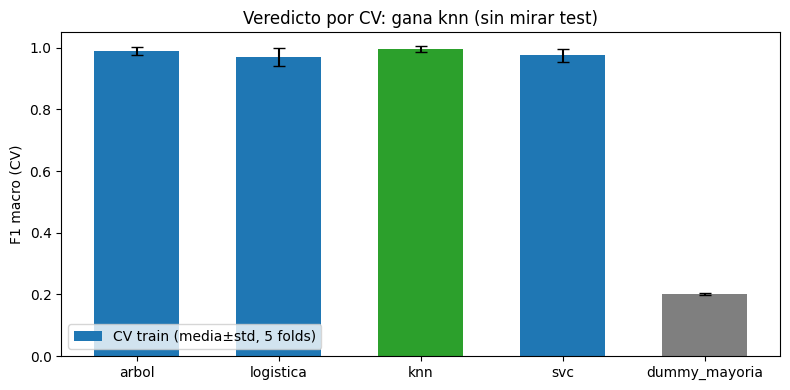

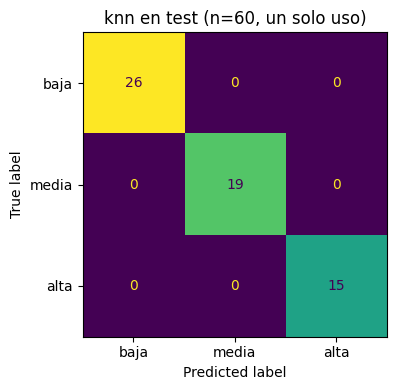

In [9]:
assert not test_tocado, "el test solo puede tocarse en esta celda"
test_tocado = True  # a partir de acá el test queda quemado: no se puede volver a decidir nada con él

# Protocolo del curso: el test confirma al ganador ya elegido por CV, no elige entre modelos.
# Solo ganador_cv toca test. Nada más se decide con este resultado.
final = {}
est = resultados[ganador_cv]["estimador"]
est.fit(Xtr, y_tr)
pred_ganador = est.predict(Xte)
final[ganador_cv] = pred_ganador

print(f"--- {ganador_cv} GANADOR POR CV (test n={len(y_te)}, un solo uso) ---")
print(f"accuracy={__import__('sklearn').metrics.accuracy_score(y_te, pred_ganador):.4f}  "
      f"f1_macro={f1_score(y_te, pred_ganador, average='macro'):.4f}")
print(classification_report(y_te, pred_ganador, digits=4))

# Figura 1: ranking por CV (lo que decide) con el ganador destacado.
fig, ax = plt.subplots(figsize=(8, 4))
nombres_m = ["arbol", "logistica", "knn", "svc", "dummy_mayoria"]
x = np.arange(len(nombres_m))
cv_mean = [resultados[m]["fold_f1"].mean() for m in nombres_m]
cv_std = [resultados[m]["fold_f1"].std() for m in nombres_m]
colores = ["tab:green" if m == ganador_cv else ("tab:gray" if m == "dummy_mayoria" else "tab:blue") for m in nombres_m]
ax.bar(x, cv_mean, width=0.6, yerr=cv_std, capsize=4, color=colores, label="CV train (media±std, 5 folds)")
ax.set_xticks(x, nombres_m)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1 macro (CV)")
ax.set_title(f"Veredicto por CV: gana {ganador_cv} (sin mirar test)")
ax.legend()
fig.tight_layout()
plt.show()

# Figura 2: matriz solo del ganador en test (confirmación, filas = realidad).
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_ganador, labels=CLASES),
                       display_labels=CLASES).plot(ax=ax, colorbar=False, values_format="d")
ax.set_title(f"{ganador_cv} en test (n={len(y_te)}, un solo uso)")
fig.tight_layout()
plt.show()


## 6. Resultados, limitaciones y lectura honesta del 1.0

- **Veredicto (CV en train, sin test)**: gana `ganador_cv` por mayor F1 macro en CV; el test solo lo confirma. No se re-ordena por test y no se desempatan modelos con test.
- La **regla exacta** da 1.0 porque *es* la etiqueta: referencia excluida del ranking, separa "aprender la regla" de "fuga". Un modelo que aproxime bien la regla llega al mismo 1.0 sin haber visto test ni IDs.
- El **baseline de mayoría** (~0.44 accuracy, ~0.20 F1 en CV) es el piso: todo modelo útil debe superarlo en CV, pero superarlo no prueba utilidad operativa.
- **Experimento distinto al backend**: acá train_full=237 (train+validación del repo) con selección por CV; el backend ajusta en 178 y elige en validación 59. Los números no son intercambiables; el entregado es el del backend (`arbol` por validación + interpretabilidad). Si CV y validación discrepan en el ganador, manda cada criterio en su experimento y se declara.
- **Limitaciones**: N=297 (train_full 237, test 60: cada error son ~1.7pp); etiqueta y 2/4 features sintéticas; foto única sin serie temporal; sin control espacial (tramos vecinos pueden caer a ambos lados del split).
- **No se afirma causalidad ni utilidad real**: el 1.0 mide ajuste a la regla sintética declarada, no que el municipio vaya a operar con 100% de acierto.


In [10]:
from sklearn.metrics import precision_score, recall_score

# Tabla honesta: CV para todos (lo que decide); test SOLO para el ganador (lo que confirma).
# Las celdas de test de los no ganadores quedan vacías a propósito.
filas = []
orden = ["arbol", "logistica", "knn", "svc", "dummy_mayoria", "regla_exacta"]
for nombre in orden:
    r = resultados[nombre]
    if nombre == ganador_cv:
        pred = final[nombre]
        test_acc = round(float(accuracy_score(y_te, pred)), 4)
        test_f1 = round(float(f1_score(y_te, pred, average="macro")), 4)
        test_prec = round(float(precision_score(y_te, pred, average="macro", zero_division=0)), 4)
        test_rec = round(float(recall_score(y_te, pred, average="macro", zero_division=0)), 4)
    else:
        test_acc = test_f1 = test_prec = test_rec = None
    fila = {
        "modelo": nombre,
        "compite": nombre in ["arbol", "logistica", "knn", "svc"],
        "ganador_cv": (nombre == ganador_cv),
        "cv_acc_media": round(float(r["fold_acc"].mean()), 4),
        "cv_acc_std": round(float(r["fold_acc"].std()), 4),
        "cv_f1_media": round(float(r["fold_f1"].mean()), 4),
        "cv_f1_std": round(float(r["fold_f1"].std()), 4),
        "best_params": json.dumps(r["best_params"], ensure_ascii=False),
        "test_acc": test_acc,
        "test_f1_macro": test_f1,
        "test_precision_macro": test_prec,
        "test_recall_macro": test_rec,
        "n_train": len(Xtr),
        "n_test": len(y_te),
    }
    for f in range(5):
        fila[f"fold{f + 1}_acc"] = round(float(r["fold_acc"][f]), 4)
        fila[f"fold{f + 1}_f1"] = round(float(r["fold_f1"][f]), 4)
    filas.append(fila)
tabla = pd.DataFrame(filas)
OUT_DIR = ROOT / "docs" / "comparacion-evaluacion"
OUT_DIR.mkdir(parents=True, exist_ok=True)
tabla.to_csv(OUT_DIR / "tabla_comparativa.csv", index=False)
print("tabla_comparativa.csv guardada:", OUT_DIR / "tabla_comparativa.csv", tabla.shape)
print(f"ganador_cv={ganador_cv} (solo esta fila tiene test; el resto queda vacío por protocolo)")
tabla[["modelo", "compite", "ganador_cv", "cv_f1_media", "cv_f1_std", "test_acc", "test_f1_macro"]].to_string(index=False)


tabla_comparativa.csv guardada: /home/nacho/Documentos/tpMachineLearningGrafo/docs/comparacion-evaluacion/tabla_comparativa.csv (6, 24)
ganador_cv=knn (solo esta fila tiene test; el resto queda vacío por protocolo)


'       modelo  compite  ganador_cv  cv_f1_media  cv_f1_std  test_acc  test_f1_macro\n        arbol     True       False       0.9898     0.0125       NaN            NaN\n    logistica     True       False       0.9695     0.0301       NaN            NaN\n          knn     True        True       0.9950     0.0099       1.0            1.0\n          svc     True       False       0.9753     0.0221       NaN            NaN\ndummy_mayoria    False       False       0.2019     0.0026       NaN            NaN\n regla_exacta    False       False       1.0000     0.0000       NaN            NaN'

In [11]:
acc_g = float(accuracy_score(y_te, final[ganador_cv]))
f1_g = float(f1_score(y_te, final[ganador_cv], average='macro'))
rank_txt = ', '.join(
    f"{m} {float(resultados[m]['fold_f1'].mean()):.4f}±{float(resultados[m]['fold_f1'].std()):.4f}"
    for m in ['arbol', 'logistica', 'knn', 'svc']
)
conclusion = (
    f"# Conclusión — comparación de evaluación (cuaderno `comparacion_evaluacion.ipynb`)\n\n"
    f"Repo auditado (solo lectura): rama `{RAMA}`, SHA `{SHA}`, `status` limpio salvo untracked ajenos a ML, "
    f"CSV con SHA idénticos a `dataset/salida/metadata.json`, seed 0, partición 178/59/60 verificada por reimplementación independiente.\n\n"
    f"Reproducción del repo (`scripts/train_compare.py --source dataset/salida/tramos.csv --seed 0`, sin escribir en el repo): "
    f"CV 5/5 folds solo en train; elegido por validación = `{REPRO['elegido']}`; "
    f"test un solo uso acc={REPRO['test'][1]} f1={REPRO['test'][2]}; baseline mayoría acc={REPRO['baseline'][0]} f1={REPRO['baseline'][1]}.\n\n"
    f"Comparación propia con protocolo del curso (train_full n=237; CV 5 folds estratificados solo en train; "
    f"`pd.get_dummies` solo con train + `StandardScaler` dentro del `Pipeline`; "
    f"`GridSearchCV(multimétrica, refit=F1)` solo en train; veredicto por CV sin mirar test; "
    f"test tocado una sola vez y solo por el ganador):\n\n"
    f"- VEREDICTO POR CV: gana `{ganador_cv}` con {float(resultados[ganador_cv]['fold_f1'].mean()):.4f}±{float(resultados[ganador_cv]['fold_f1'].std()):.4f} (F1) "
    f"y params {resultados[ganador_cv]['best_params']}. Ranking CV: {rank_txt}. "
    f"Dummy (piso, no compite): {float(resultados['dummy_mayoria']['fold_f1'].mean()):.4f}. Regla exacta (referencia, no compite): 1.0.\n"
    f"- CONFIRMACIÓN EN TEST (solo ganador, n=60, un solo uso): `{ganador_cv}` acc={acc_g:.4f} f1={f1_g:.4f}. "
    f"Los demás modelos no tocan test (celdas vacías en la tabla) para no re-elegir por test.\n"
    f"- Experimento distinto al backend: acá se selecciona por CV sobre 237; el backend selecciona en validación 59 (train 178) "
    f"y entrega `{REPRO['elegido']}`. No son intercambiables; el modelo entregado es el del backend.\n\n"
    f"Evidencia del curso: `train_test_split` estratificado S5 `notebook-1-metricas` celda 5; baseline ingenuo S5 `notebook-1` celda 7; "
    f"`make_pipeline(StandardScaler(), ...)` S5 `notebook-1` celda 9 y S4 `notebook-2-knn-svm` celdas 37-38 (árbol sin escala); "
    f"matriz filas=real y `classification_report` S5 `notebook-1` celdas 13-14/18-24; CV 5 folds y `mean±std` S5 `notebook-2-validacion-cruzada` celdas 6/9/10/12; "
    f"protocolo test-intocable + elegir con CV en train + `GridSearchCV` S5 `notebook-2` celdas 13-18; "
    f"todo-dentro-del-pipeline S5 `notebook-2` celdas 26-27; `pd.get_dummies` S2 `notebook-2-preprocesamiento` celda 8.\n\n"
    f"Fuga: no detectada en train/test (sin columna `score`, IDs fuera de `X`, preprocesamiento sin ajustar fuera de folds, "
    f"test un solo uso solo por el ganador). La circularidad regla↔etiqueta es declarada por el Enunciado, no una fuga. "
    f"La CV reportada es métrica de selección (`best_index_` de `GridSearchCV`), no estimación independiente del procedimiento (eso pediría CV anidada).\n\n"
    f"Limitaciones: N=297 (cada error en test ≈1.7pp); etiqueta y 2/4 features sintéticas; foto única sin serie temporal; "
    f"sin control espacial; el 1.0 mide ajuste a la regla, **no causalidad ni utilidad operativa real**.\n"
    f"<!-- FIN -->\n"
)
OUT_DIR = ROOT / "docs" / "comparacion-evaluacion"
OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "CONCLUSION.md").write_text(conclusion)
assert (OUT_DIR / "CONCLUSION.md").read_text().rstrip().endswith("<!-- FIN -->")
print("CONCLUSION.md guardada y termina con <!-- FIN -->.")
print(conclusion)


CONCLUSION.md guardada y termina con <!-- FIN -->.
# Conclusión — comparación de evaluación (cuaderno `comparacion_evaluacion.ipynb`)

Repo auditado (solo lectura): rama `main`, SHA `97f10409a29e231dd01bf5c06ae36dd32f58c65b`, `status` limpio salvo untracked ajenos a ML, CSV con SHA idénticos a `dataset/salida/metadata.json`, seed 0, partición 178/59/60 verificada por reimplementación independiente.

Reproducción del repo (`scripts/train_compare.py --source dataset/salida/tramos.csv --seed 0`, sin escribir en el repo): CV 5/5 folds solo en train; elegido por validación = `arbol`; test un solo uso acc=1.0000 f1=1.0000; baseline mayoría acc=0.4407 f1=0.2039.

Comparación propia con protocolo del curso (train_full n=237; CV 5 folds estratificados solo en train; `pd.get_dummies` solo con train + `StandardScaler` dentro del `Pipeline`; `GridSearchCV(multimétrica, refit=F1)` solo en train; veredicto por CV sin mirar test; test tocado una sola vez y solo por el ganador):

- VEREDICTO POR CV: g